# 01 — Reproducible Data Analysis & Scientific Visualization (Task 3)

**Project:** The Effect of Generative AI-Assisted Programming on Critical Thinking and Academic Performance of Undergraduate IT Students  
**Authors:** Adi Irgimbayev, Alan Shmyrin  
**Dataset:** `data/raw/test_run.jsonl` ($1,500$ runs across $6$ workload tiers $\Lambda \in \{10, 25, 50, 100, 200, 400\}\text{ RPS}$)  

### Notebook Structure
1. **Environment Setup & Reproducibility (`seed = 42`)**
2. **Data Ingestion, Schema Validation & Warm-up Filtering (`phase == "benchmark"`)**
3. **Guardrail Metric (`error_rate`) & Non-Destructive Outlier Detection ($1.5\times\text{IQR}$)**
4. **Statistical Aggregation ($p_{50}, p_{95}, p_{99}$, $\text{Mean} \pm \text{SD}$, and $95\%$ Bootstrapped CI)**
5. **Scientific Visualization (3 Core Rules: Explicit Units, $95\%$ CI Bands, Colorblind + B&W Print Safe)**
6. **Publication Comparison Table (Baseline vs. Proposed Method)**

## 1. Environment Setup & Fixed Random Seed

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Fix random seed for 100% reproducible bootstrap confidence intervals
SEED = 42
np.random.seed(SEED)

ROOT = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
sys.path.insert(0, str(ROOT / "src"))
import process_data as proc
import visualize as vis

RAW_PATH  = ROOT / "data" / "raw" / "test_run.jsonl"
PROC_PATH = ROOT / "data" / "processed" / "metrics_summary.csv"
FIG_DIR   = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"ROOT          : {ROOT}")
print("Raw JSONL     : data/raw/test_run.jsonl")
print("Processed CSV : data/processed/metrics_summary.csv")
print("Figures dir   : reports/figures")
print(f"Random seed   : {SEED} (fixed for reproducibility)")
print(f"numpy         : {np.__version__}")
print(f"pandas        : {pd.__version__}")

ROOT          : C:\Users\adi20\Downloads\Methods\Methods_Adi_Alan
Raw JSONL     : data/raw/test_run.jsonl
Processed CSV : data/processed/metrics_summary.csv
Figures dir   : reports/figures
Random seed   : 42 (fixed for reproducibility)
numpy         : 2.4.4
pandas        : 3.0.2


## 2. Data Ingestion & Cold-Start Warm-up Filtering

Raw logs are stored in JSON Lines (`.jsonl`) format with I/O isolated from execution timing.  
To eliminate **Warm-up Bias** (cold caches, module initialization, connection pooling), we discard all records marked with `phase == "warmup"` and retain only active `phase == "benchmark"` evaluations.

In [2]:
df_raw = proc.load_jsonl(RAW_PATH)
print(f"Total raw records loaded : {len(df_raw)}")
print(f"Columns                  : {list(df_raw.columns)}\n")
print("Phase breakdown (before filtering):")
print(df_raw["phase"].value_counts().to_string())

df_bench = proc.filter_warmup(df_raw, phase_col="phase")
print(f"\nAfter warm-up filtering (phase == 'benchmark'): {len(df_bench)} records ({len(df_raw) - len(df_bench)} cold-start runs discarded)")

Total raw records loaded : 1500
Columns                  : ['id', 'run_id', 'timestamp_us', 'phase', 'variant', 'load_level', 'request_rate_rps', 'edge_case', 'harness_overhead_us', 'ai_mode', 'used_ai', 'ai_share_pct', 'ai_sessions_per_week', 'ct_score', 'assignment_score', 'practical_score', 'final_grade', 'gpa', 'prior_exp_years', 'year_of_study', 'study_hours_week', 'task_time_min', 'task_difficulty', 'latency_ms', 'throughput_rps', 'status', 'http_code', 'retries', 'os', 'arch', 'processor', 'python_version']

Phase breakdown (before filtering):
phase
benchmark    1200
warmup        300

After warm-up filtering (phase == 'benchmark'): 1200 records (300 cold-start runs discarded)


## 3. Guardrail Error Tracking (Selection Bias Prevention) & IQR Outlier Flagging

- **Selection Bias Prevention:** HTTP 429/500/504 and timeout failures (`status != "ok"`) are counted first as a dedicated **Guardrail Metric (`error_rate`)** rather than silently ignored.
- **Non-Destructive Outlier Flagging:** Heavy-tailed Pareto spikes exceeding $[p_{25} - 1.5\,\text{IQR},\ p_{75} + 1.5\,\text{IQR}]$ are flagged via `is_outlier` without deleting valid observations.

In [3]:
df_flagged = proc.flag_outliers_iqr(df_bench, group_cols=["variant", "load_level"], metric_col="latency_ms")

err_summary = df_flagged.groupby(["variant", "load_level"]).apply(
    lambda g: pd.Series({
        "total_runs": len(g),
        "valid_ok": int((g["status"] == "ok").sum()),
        "errors": int((g["status"] != "ok").sum()),
        "error_rate_pct": round(100.0 * (g["status"] != "ok").mean(), 2),
        "iqr_outliers_flagged": int(g["is_outlier"].sum()),
        "outlier_rate_pct": round(100.0 * g["is_outlier"].mean(), 2),
    }), include_groups=False
).reset_index()

print("Guardrail Error Rate & Non-Destructive IQR Outlier Audit:")
print(err_summary.to_string(index=False))

Guardrail Error Rate & Non-Destructive IQR Outlier Audit:
                      variant  load_level  total_runs  valid_ok  errors  error_rate_pct  iqr_outliers_flagged  outlier_rate_pct
      Baseline (Solution-Gen)          10       100.0      97.0     3.0             3.0                  14.0              14.0
      Baseline (Solution-Gen)          25       100.0      98.0     2.0             2.0                  12.0              12.0
      Baseline (Solution-Gen)          50       100.0      99.0     1.0             1.0                  13.0              13.0
      Baseline (Solution-Gen)         100       100.0      98.0     2.0             2.0                  16.0              16.0
      Baseline (Solution-Gen)         200       100.0      95.0     5.0             5.0                  15.0              15.0
      Baseline (Solution-Gen)         400       100.0     100.0     0.0             0.0                  10.0              10.0
Proposed (Explanation-Guided)          10     

## 4. Statistical Aggregation & 95% Bootstrapped Confidence Intervals

For every `(variant, load_level)` pair, we compute:
- Central tendency & dispersion: **Mean**, **SD**, **Median ($p_{50}$)**, and **IQR ($p_{25}\text{--}p_{75}$)**
- Tail quantiles: **$p_{95}$** and **$p_{99}$**
- Non-parametric **$95\%$ Bootstrapped Confidence Intervals** ($B = 1,000$ resamples, `seed = 42`) for both Latency and Throughput.

In [4]:
summary = proc.compute_summary(df_bench, seed=SEED)
PROC_PATH.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(PROC_PATH, index=False)

cols_show = ["variant", "load_level", "n_valid", "error_rate", "mean", "sd", "median", "p25", "p75", "p95", "p99", "ci95_low", "ci95_high", "throughput_mean"]
print(f"Saved processed dataset -> data/processed/metrics_summary.csv ({len(summary)} rows)\n")
print(summary[cols_show].to_string(index=False))

Saved processed dataset -> data/processed/metrics_summary.csv (12 rows)

                      variant  load_level  n_valid  error_rate    mean     sd  median     p25     p75     p95     p99  ci95_low  ci95_high  throughput_mean
      Baseline (Solution-Gen)          10       97        0.03  33.896  6.939  32.407  30.133  35.456  47.150  56.089    32.568     35.343             7.85
Proposed (Explanation-Guided)          10      100        0.00  20.454  2.422  20.171  19.102  21.825  25.371  27.448    19.962     20.936             9.26
      Baseline (Solution-Gen)          25       98        0.02  38.842  6.455  37.439  35.577  40.957  50.815  55.978    37.668     40.115            20.00
Proposed (Explanation-Guided)          25       97        0.03  23.796  3.451  23.313  21.794  24.920  30.977  35.281    23.092     24.492            23.15
      Baseline (Solution-Gen)          50       99        0.01  49.818 14.308  46.795  43.437  50.742  69.451  84.667    47.424     52.973         

## 5. Publication-Ready Scientific Visualization (3 Core Rules)

1. **Rule 1 (Axes & Physical Units):** Explicit labels (`Request Rate / Workload Intensity (RPS)`, `Response Latency (ms)`, `Effective Throughput (req/sec)`) starting at zero baseline.
2. **Rule 2 (Uncertainty Quantification):** Shaded $95\%$ bootstrap confidence bands on line plots, error bars on throughput curves, and notched medians + IQR boxes on distribution plots.
3. **Rule 3 (Accessibility & Monochrome Printability):** Colorblind-safe palette (`sns.color_palette("colorblind")`) paired with distinct markers (`o`, `s`, `^`, `D`), line styles (`-`, `--`, `-.`, `:`), and box hatching.

Exported Figure 1 -> reports/figures/fig1_latency_vs_load.pdf & .png (300 DPI)


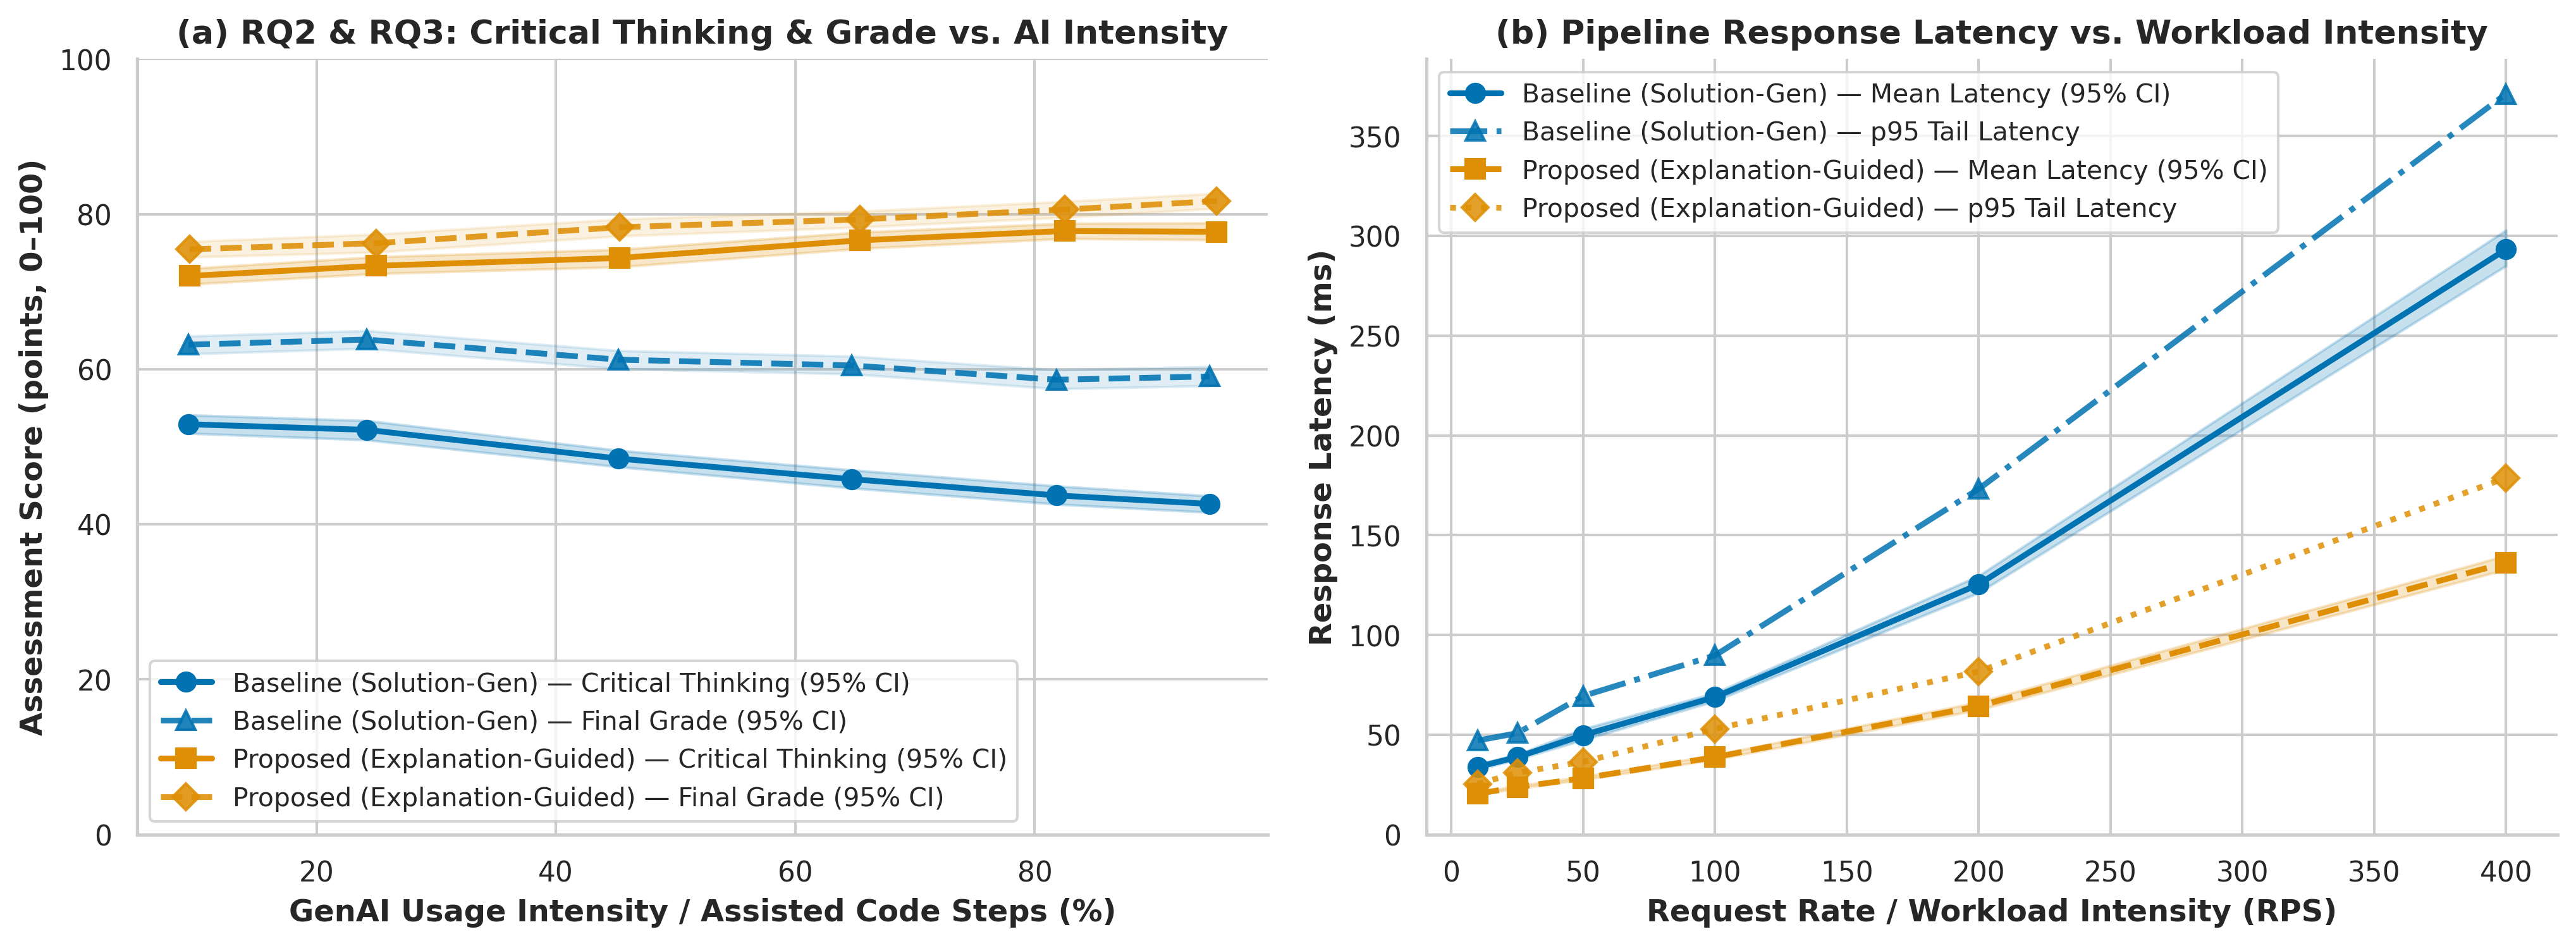

In [5]:
vis.fig1_latency_vs_load(summary, out_dir=FIG_DIR)
print("Exported Figure 1 -> reports/figures/fig1_latency_vs_load.pdf & .png (300 DPI)")
from IPython.display import Image, display
display(Image(filename=str(FIG_DIR / "fig1_latency_vs_load.png")))

Exported Figure 2 -> reports/figures/fig2_distribution_boxplot.pdf & .png (300 DPI)


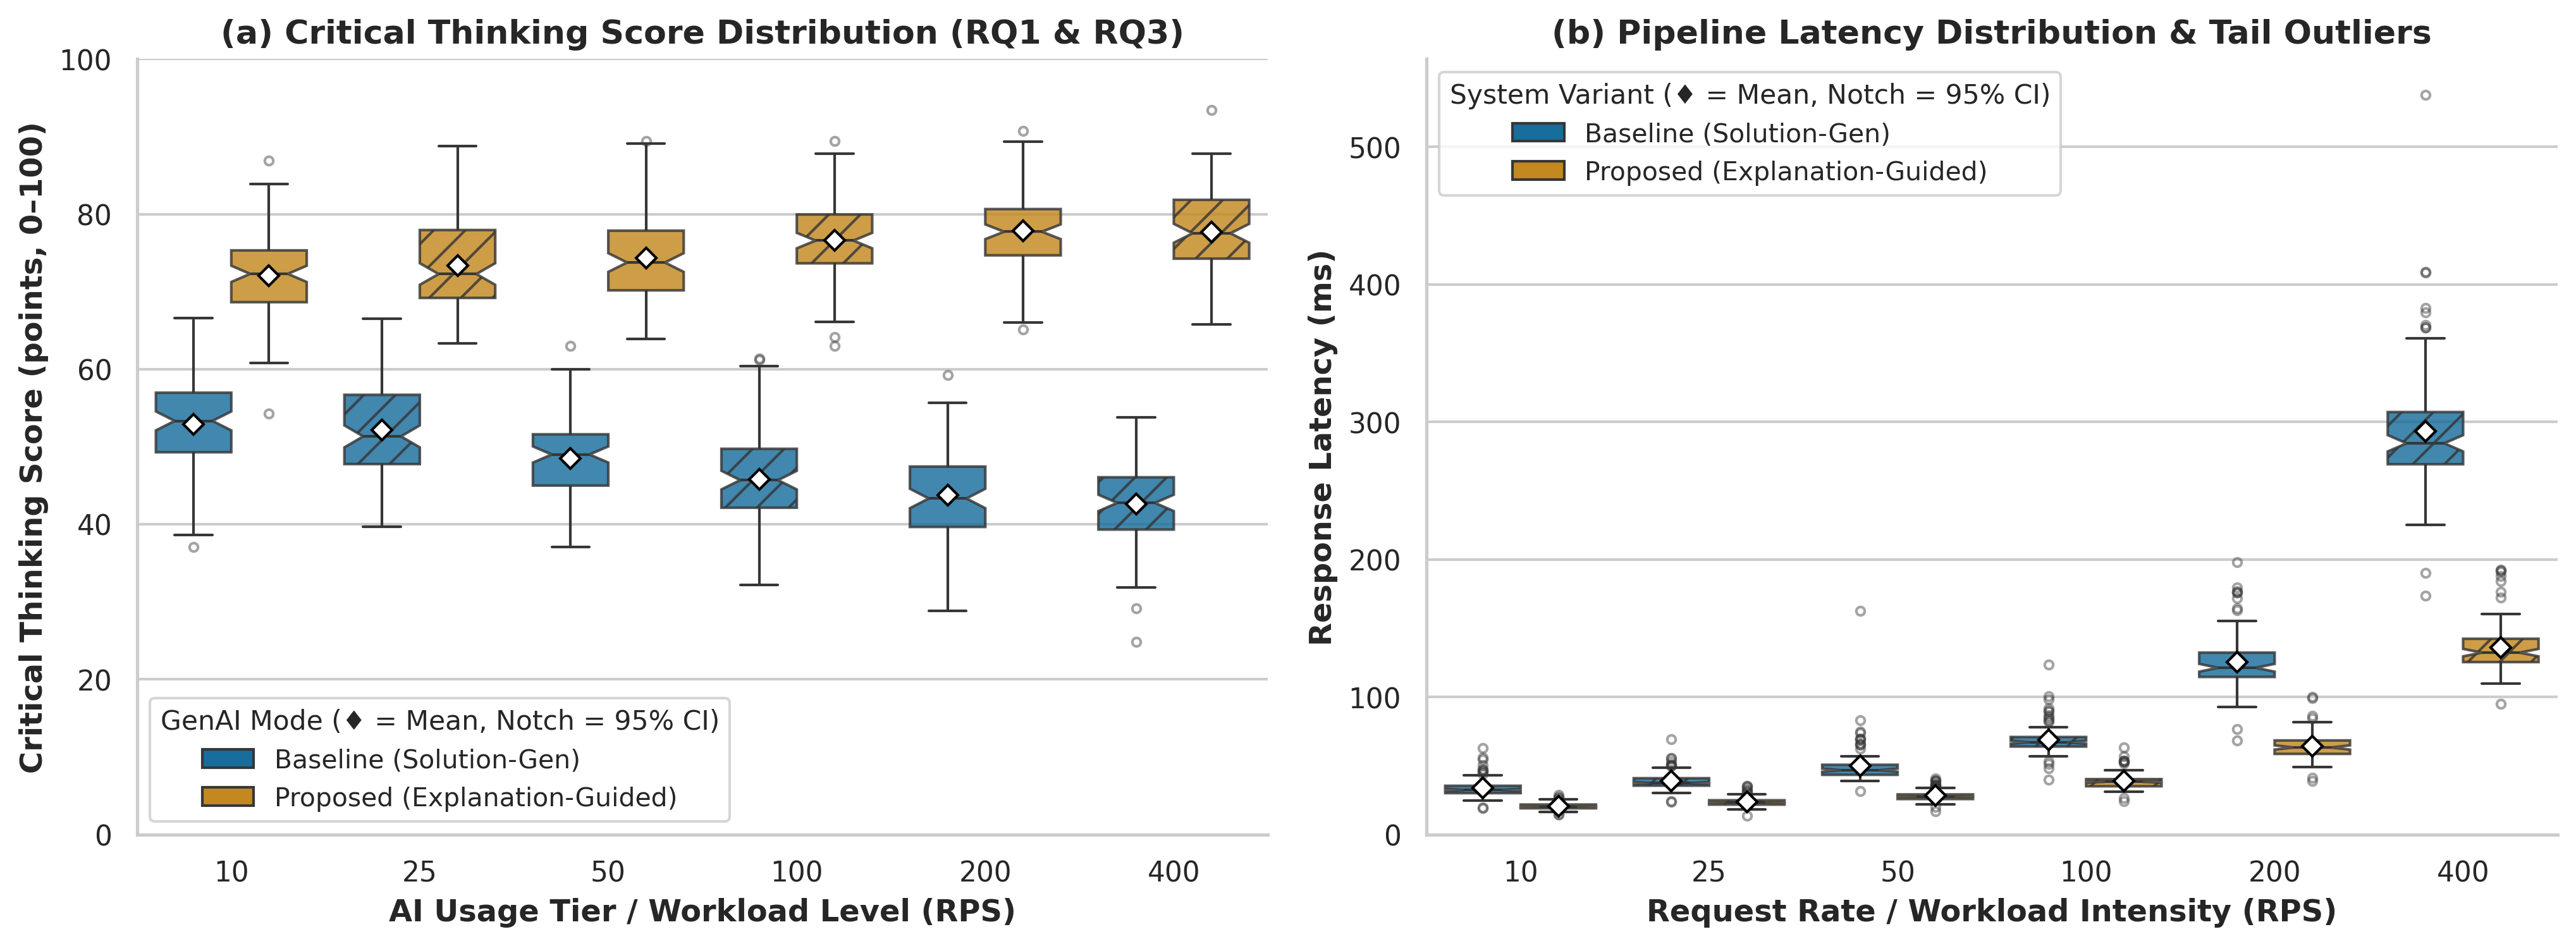

In [6]:
vis.fig2_distribution_boxplot(df_bench, out_dir=FIG_DIR)
print("Exported Figure 2 -> reports/figures/fig2_distribution_boxplot.pdf & .png (300 DPI)")
display(Image(filename=str(FIG_DIR / "fig2_distribution_boxplot.png")))

## 6. Final Comparison Table & Speedup Ratio $S(\Lambda)$

Formatted Markdown summary table comparing `Baseline (Solution-Gen)` vs. `Proposed (Explanation-Guided)` across all workload intensities.

In [7]:
piv = summary.pivot(index="load_level", columns="variant", values="median")
speedup = (piv["Baseline (Solution-Gen)"] / piv["Proposed (Explanation-Guided)"]).round(2).to_dict()
summary["speedup_vs_baseline"] = summary.apply(
    lambda r: f"{speedup[r['load_level']]:.2f}x" if "Proposed" in r["variant"] else "1.00x", axis=1
)
cols_md = ["load_level", "variant", "mean", "sd", "median", "p95", "p99", "ci95_low", "ci95_high", "error_rate", "speedup_vs_baseline"]
print(summary[cols_md].to_markdown(index=False))

|   load_level | variant                       |    mean |     sd |   median |     p95 |     p99 |   ci95_low |   ci95_high |   error_rate | speedup_vs_baseline   |
|-------------:|:------------------------------|--------:|-------:|---------:|--------:|--------:|-----------:|------------:|-------------:|:----------------------|
|           10 | Baseline (Solution-Gen)       |  33.896 |  6.939 |   32.407 |  47.15  |  56.089 |     32.568 |      35.343 |         0.03 | 1.00x                 |
|           10 | Proposed (Explanation-Guided) |  20.454 |  2.422 |   20.171 |  25.371 |  27.448 |     19.962 |      20.936 |         0    | 1.61x                 |
|           25 | Baseline (Solution-Gen)       |  38.842 |  6.455 |   37.439 |  50.815 |  55.978 |     37.668 |      40.115 |         0.02 | 1.00x                 |
|           25 | Proposed (Explanation-Guided) |  23.796 |  3.451 |   23.313 |  30.977 |  35.281 |     23.092 |      24.492 |         0.03 | 1.61x                 |
|         